In [1]:
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
import shap

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    roc_curve, auc, precision_recall_curve
)

c:\Users\MICROSOFT SURFACE\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
X_test_df = pd.read_csv("X_test_features.csv")
y_test = np.load("y_test.npy")

lgbm = joblib.load("lgbm_model.joblib")
rf = joblib.load("rf_model.joblib")
mlp = joblib.load("mlp_model.joblib")

lgbm_training_time = joblib.load("lgbm_training_time.joblib")
rf_training_time = joblib.load("rf_training_time.joblib")
mlp_training_time = joblib.load("mlp_training_time.joblib")

# Needed again only for SHAP background samples
X_train_df = pd.read_csv("X_train_features.csv")

print("Test Shape:", X_test_df.shape)

Test Shape: (41936, 60)


In [3]:
# ============================================================
# PREDICTION
# ============================================================
y_pred_lgbm = lgbm.predict(X_test_df)
probability_lgbm = lgbm.predict_proba(X_test_df)[:, 1]

In [4]:
# ============================================================
# PERFORMANCE METRICS
# ============================================================
lgbm_accuracy = accuracy_score(y_test, y_pred_lgbm)
lgbm_precision = precision_score(y_test, y_pred_lgbm)
lgbm_recall = recall_score(y_test, y_pred_lgbm)
lgbm_f1 = f1_score(y_test, y_pred_lgbm)
lgbm_auc = roc_auc_score(y_test, probability_lgbm)

print("="*60)
print("MODEL PERFORMANCE")
print("="*60)
print(f"Accuracy : {lgbm_accuracy:.4f}")
print(f"Precision: {lgbm_precision:.4f}")
print(f"Recall   : {lgbm_recall:.4f}")
print(f"F1 Score : {lgbm_f1:.4f}")
print(f"ROC AUC  : {lgbm_auc:.4f}")

MODEL PERFORMANCE
Accuracy : 0.9443
Precision: 0.9137
Recall   : 0.9814
F1 Score : 0.9463
ROC AUC  : 0.9898


In [5]:
# ============================================================
# CLASSIFICATION REPORT
# ============================================================
print(classification_report(y_test, y_pred_lgbm, digits=4))

              precision    recall  f1-score   support

           0     0.9799    0.9073    0.9422     20968
           1     0.9137    0.9814    0.9463     20968

    accuracy                         0.9443     41936
   macro avg     0.9468    0.9443    0.9442     41936
weighted avg     0.9468    0.9443    0.9442     41936



In [6]:
# ============================================================
# RESULTS TABLE
# ============================================================
lgbm_results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score", "ROC AUC", "Training Time (sec)"],
    "Value": [lgbm_accuracy, lgbm_precision, lgbm_recall, lgbm_f1, lgbm_auc, lgbm_training_time]
})
display(lgbm_results)

,Metric,Value
0,Accuracy,0.944320
1,Precision,0.913681
2,Recall,0.981353
3,F1 Score,0.946308
4,ROC AUC,0.989781
5,Training Time (sec),114.594457


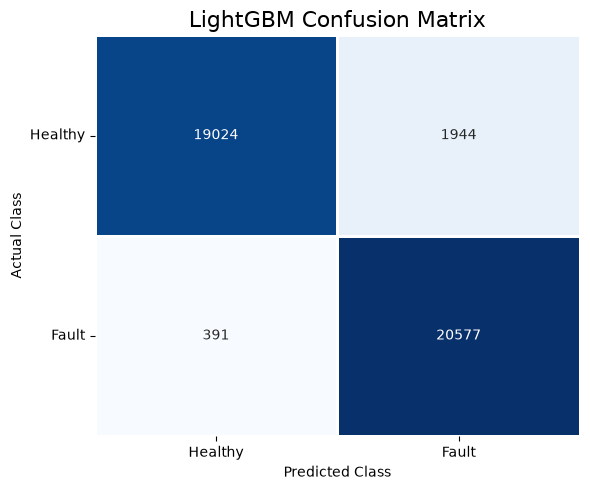

In [7]:
# ============================================================
# CONFUSION MATRIX
# ============================================================
cm_lgbm = confusion_matrix(y_test, y_pred_lgbm)

plt.figure(figsize=(6,5))
sns.heatmap(cm_lgbm, annot=True, fmt='d', cmap='Blues', linewidths=1, cbar=False)
plt.title("LightGBM Confusion Matrix", fontsize=16)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks([0.5,1.5], ["Healthy","Fault"])
plt.yticks([0.5,1.5], ["Healthy","Fault"], rotation=0)
plt.tight_layout()
plt.show()

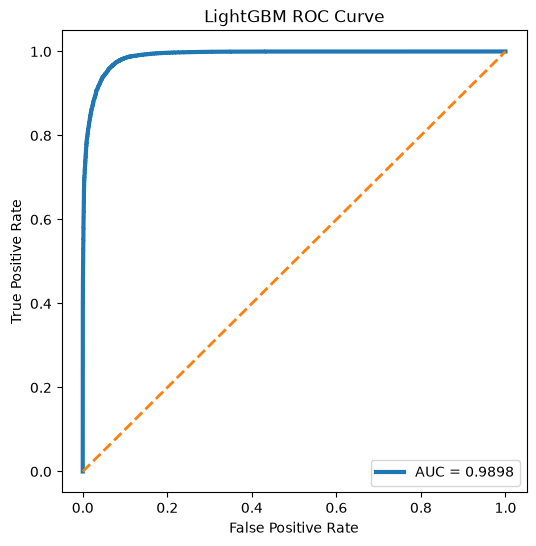

In [8]:
# ============================================================
# ROC CURVE
# ============================================================
fpr_lgbm, tpr_lgbm, _ = roc_curve(y_test, probability_lgbm)
roc_auc_lgbm = auc(fpr_lgbm, tpr_lgbm)

plt.figure(figsize=(6,6))
plt.plot(fpr_lgbm, tpr_lgbm, linewidth=3, label=f"AUC = {roc_auc_lgbm:.4f}")
plt.plot([0,1],[0,1], linestyle='--', linewidth=2)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("LightGBM ROC Curve")
plt.legend()
plt.show()

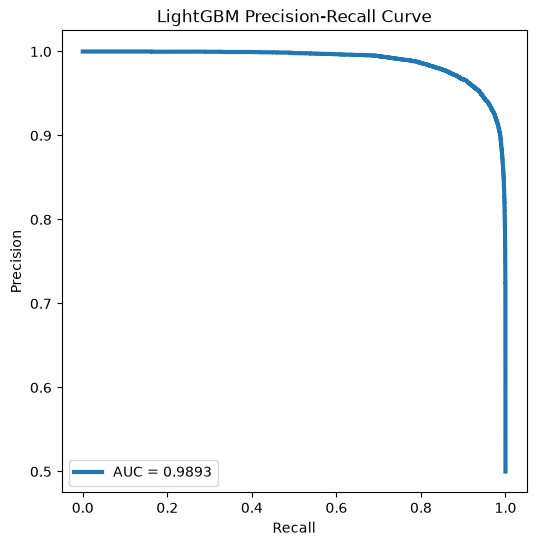

In [9]:
# ============================================================
# PRECISION RECALL CURVE
# ============================================================
precision_curve_lgbm, recall_curve_lgbm, _ = precision_recall_curve(y_test, probability_lgbm)
pr_auc_lgbm = auc(recall_curve_lgbm, precision_curve_lgbm)

plt.figure(figsize=(6,6))
plt.plot(recall_curve_lgbm, precision_curve_lgbm, linewidth=3, label=f"AUC = {pr_auc_lgbm:.4f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("LightGBM Precision-Recall Curve")
plt.legend()
plt.show()

c:\Users\MICROSOFT SURFACE\AppData\Local\Programs\Python\Python313\Lib\site-packages\shap\explainers\_tree.py:632: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


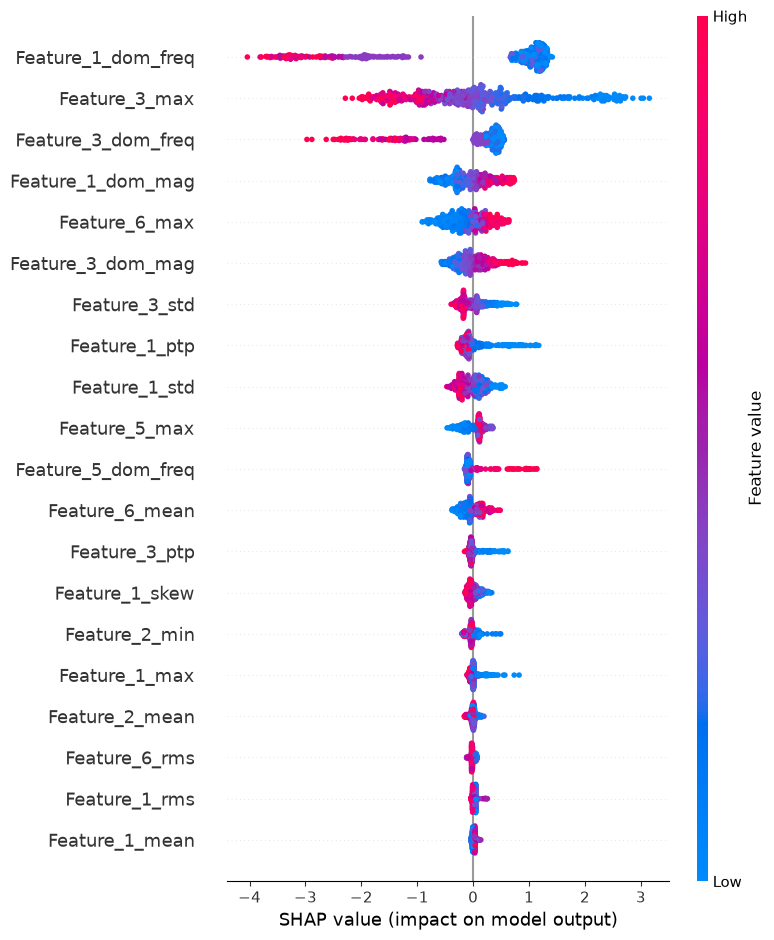

In [10]:
# ============================================================
# SHAP EXPLAINABILITY (LightGBM)
# ============================================================
explainer_lgbm = shap.TreeExplainer(lgbm)
sample_lgbm = X_train_df.sample(min(500, len(X_train_df)), random_state=42)
shap_values_lgbm = explainer_lgbm.shap_values(sample_lgbm)

shap.summary_plot(
    shap_values_lgbm[1] if isinstance(shap_values_lgbm, list) else shap_values_lgbm,
    sample_lgbm
)

In [11]:
# ============================================
# PREDICTION
# ============================================

y_pred_rf = rf.predict(X_test_df)
probability_rf = rf.predict_proba(X_test_df)[:, 1]

In [12]:
# ============================================================
# PERFORMANCE METRICS
# ============================================================
rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf)
rf_recall = recall_score(y_test, y_pred_rf)
rf_f1 = f1_score(y_test, y_pred_rf)
rf_auc = roc_auc_score(y_test, probability_rf)

print("="*60)
print("MODEL PERFORMANCE")
print("="*60)
print(f"Accuracy : {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall   : {rf_recall:.4f}")
print(f"F1 Score : {rf_f1:.4f}")
print(f"ROC AUC  : {rf_auc:.4f}")

MODEL PERFORMANCE
Accuracy : 0.9308
Precision: 0.9072
Recall   : 0.9597
F1 Score : 0.9327
ROC AUC  : 0.9811


In [13]:
# ============================================================
# CLASSIFICATION REPORT
# ============================================================
print(classification_report(y_test, y_pred_rf, digits=4))

              precision    recall  f1-score   support

           0     0.9572    0.9018    0.9287     20968
           1     0.9072    0.9597    0.9327     20968

    accuracy                         0.9308     41936
   macro avg     0.9322    0.9308    0.9307     41936
weighted avg     0.9322    0.9308    0.9307     41936



In [14]:
# ============================================================
# RESULTS TABLE
# ============================================================
rf_results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score", "ROC AUC", "Training Time (sec)"],
    "Value": [rf_accuracy, rf_precision, rf_recall, rf_f1, rf_auc, rf_training_time]
})
display(rf_results)

,Metric,Value
0,Accuracy,0.930752
1,Precision,0.907177
2,Recall,0.959700
3,F1 Score,0.932700
4,ROC AUC,0.981065
5,Training Time (sec),651.381311


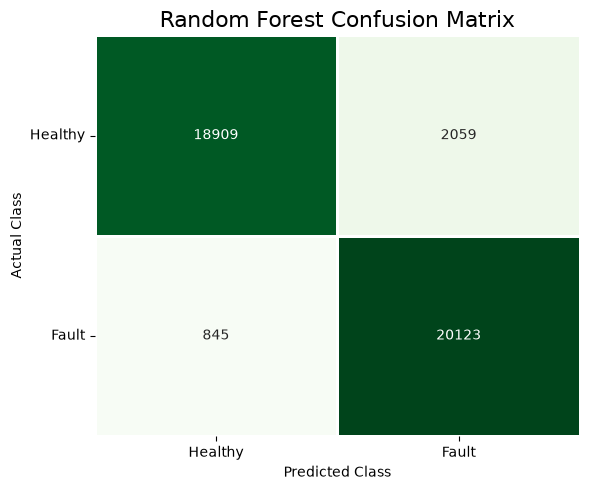

In [15]:
# ============================================================
# CONFUSION MATRIX
# ============================================================
cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6,5))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens', linewidths=1, cbar=False)
plt.title("Random Forest Confusion Matrix", fontsize=16)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks([0.5,1.5], ["Healthy","Fault"])
plt.yticks([0.5,1.5], ["Healthy","Fault"], rotation=0)
plt.tight_layout()
plt.show()

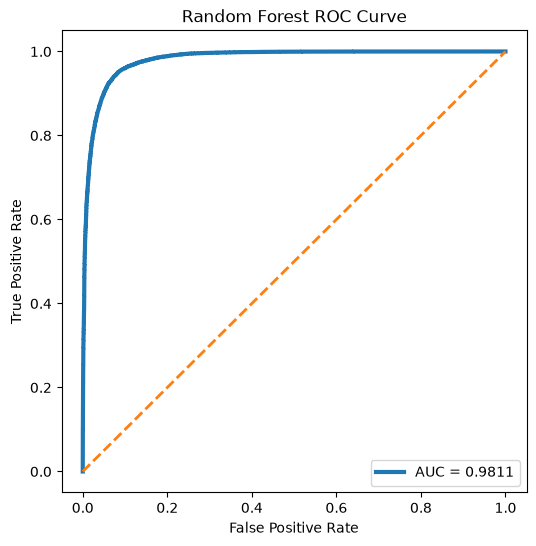

In [16]:
# ============================================================
# ROC CURVE
# ============================================================
fpr_rf, tpr_rf, _ = roc_curve(y_test, probability_rf)
roc_auc_rf = auc(fpr_rf, tpr_rf)

plt.figure(figsize=(6,6))
plt.plot(fpr_rf, tpr_rf, linewidth=3, label=f"AUC = {roc_auc_rf:.4f}")
plt.plot([0,1],[0,1], linestyle='--', linewidth=2)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Random Forest ROC Curve")
plt.legend()
plt.show()

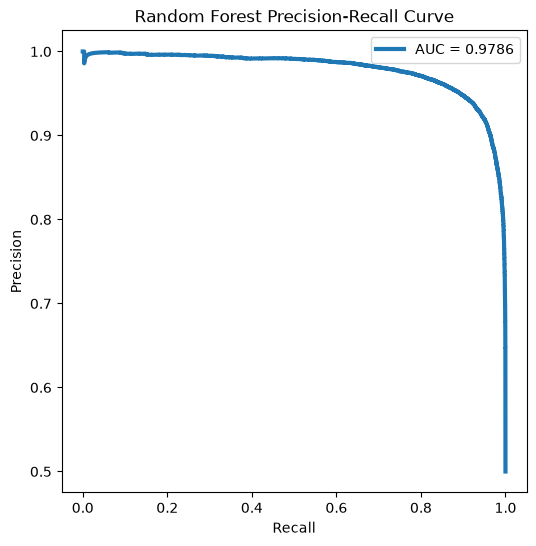

In [17]:
# ============================================================
# PRECISION RECALL CURVE
# ============================================================
precision_curve_rf, recall_curve_rf, _ = precision_recall_curve(y_test, probability_rf)
pr_auc_rf = auc(recall_curve_rf, precision_curve_rf)

plt.figure(figsize=(6,6))
plt.plot(recall_curve_rf, precision_curve_rf, linewidth=3, label=f"AUC = {pr_auc_rf:.4f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Random Forest Precision-Recall Curve")
plt.legend()
plt.show()

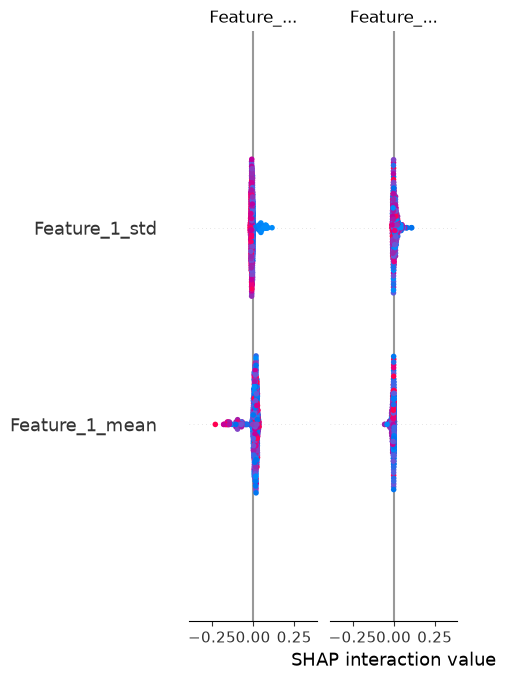

In [18]:
# ============================================================
# SHAP EXPLAINABILITY (Random Forest)
# ============================================================
explainer_rf = shap.TreeExplainer(rf)
sample_rf = X_train_df.sample(min(500, len(X_train_df)), random_state=42)
shap_values_rf = explainer_rf.shap_values(sample_rf)

shap.summary_plot(
    shap_values_rf[1] if isinstance(shap_values_rf, list) else shap_values_rf,
    sample_rf
)

In [19]:
# ============================================================
# PREDICTION
# ============================================================
y_pred_mlp = mlp.predict(X_test_df)
probability_mlp = mlp.predict_proba(X_test_df)[:, 1]

In [20]:
# ============================================================
# PERFORMANCE METRICS
# ============================================================
mlp_accuracy = accuracy_score(y_test, y_pred_mlp)
mlp_precision = precision_score(y_test, y_pred_mlp)
mlp_recall = recall_score(y_test, y_pred_mlp)
mlp_f1 = f1_score(y_test, y_pred_mlp)
mlp_auc = roc_auc_score(y_test, probability_mlp)

print("="*60)
print("MODEL PERFORMANCE")
print("="*60)
print(f"Accuracy : {mlp_accuracy:.4f}")
print(f"Precision: {mlp_precision:.4f}")
print(f"Recall   : {mlp_recall:.4f}")
print(f"F1 Score : {mlp_f1:.4f}")
print(f"ROC AUC  : {mlp_auc:.4f}")

MODEL PERFORMANCE
Accuracy : 0.9731
Precision: 0.9776
Recall   : 0.9684
F1 Score : 0.9730
ROC AUC  : 0.9968


In [21]:
# ============================================================
# CLASSIFICATION REPORT
# ============================================================
print(classification_report(y_test, y_pred_mlp, digits=4))

              precision    recall  f1-score   support

           0     0.9687    0.9778    0.9732     20968
           1     0.9776    0.9684    0.9730     20968

    accuracy                         0.9731     41936
   macro avg     0.9731    0.9731    0.9731     41936
weighted avg     0.9731    0.9731    0.9731     41936



In [22]:
# ============================================================
# RESULTS TABLE
# ============================================================
mlp_results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score", "ROC AUC", "Training Time (sec)"],
    "Value": [mlp_accuracy, mlp_precision, mlp_recall, mlp_f1, mlp_auc, mlp_training_time]
})
display(mlp_results)

,Metric,Value
0,Accuracy,0.973102
1,Precision,0.977566
2,Recall,0.968428
3,F1 Score,0.972976
4,ROC AUC,0.996764
5,Training Time (sec),958.569589


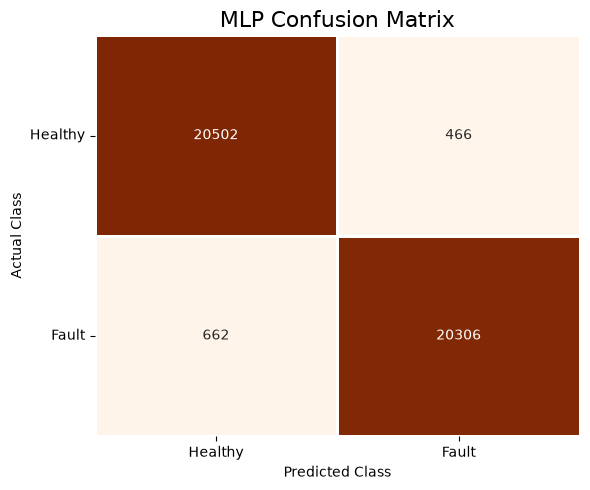

In [23]:
# ============================================================
# CONFUSION MATRIX
# ============================================================
cm_mlp = confusion_matrix(y_test, y_pred_mlp)

plt.figure(figsize=(6,5))
sns.heatmap(cm_mlp, annot=True, fmt='d', cmap='Oranges', linewidths=1, cbar=False)
plt.title("MLP Confusion Matrix", fontsize=16)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks([0.5,1.5], ["Healthy","Fault"])
plt.yticks([0.5,1.5], ["Healthy","Fault"], rotation=0)
plt.tight_layout()
plt.show()

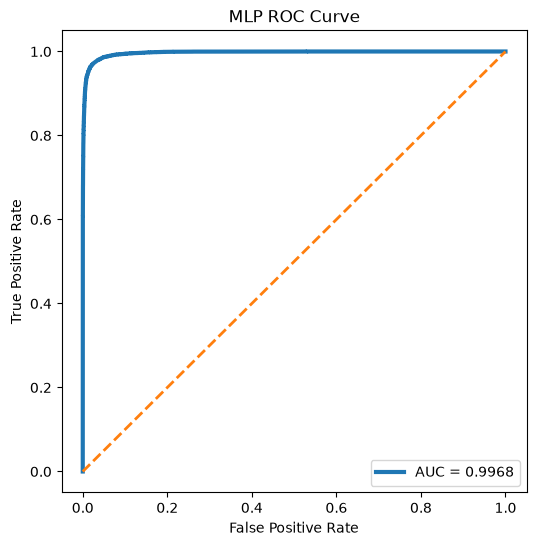

In [24]:
# ============================================================
# ROC CURVE
# ============================================================
fpr_mlp, tpr_mlp, _ = roc_curve(y_test, probability_mlp)
roc_auc_mlp = auc(fpr_mlp, tpr_mlp)

plt.figure(figsize=(6,6))
plt.plot(fpr_mlp, tpr_mlp, linewidth=3, label=f"AUC = {roc_auc_mlp:.4f}")
plt.plot([0,1],[0,1], linestyle='--', linewidth=2)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("MLP ROC Curve")
plt.legend()
plt.show()

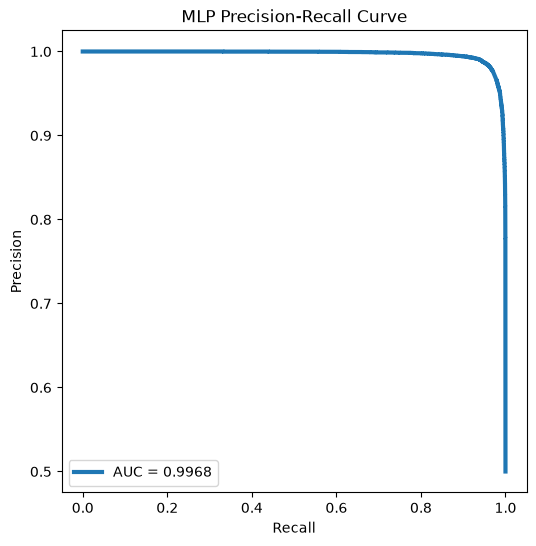

In [25]:
# ============================================================
# PRECISION RECALL CURVE
# ============================================================
precision_curve_mlp, recall_curve_mlp, _ = precision_recall_curve(y_test, probability_mlp)
pr_auc_mlp = auc(recall_curve_mlp, precision_curve_mlp)

plt.figure(figsize=(6,6))
plt.plot(recall_curve_mlp, precision_curve_mlp, linewidth=3, label=f"AUC = {pr_auc_mlp:.4f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("MLP Precision-Recall Curve")
plt.legend()
plt.show()

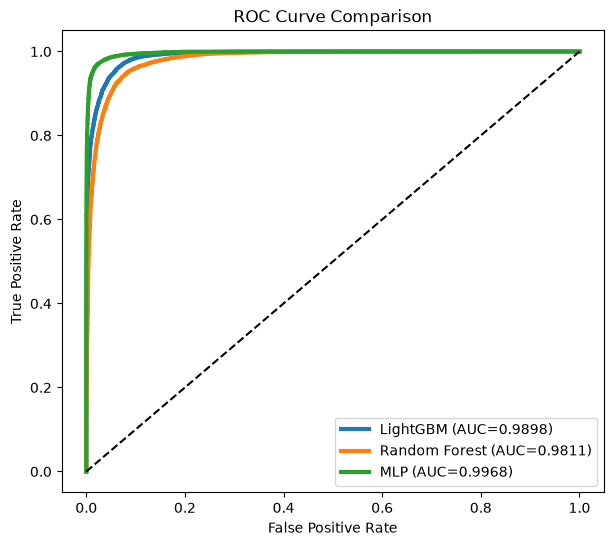

In [26]:
# ============================================================
# COMBINED ROC CURVE
# ============================================================
plt.figure(figsize=(7,6))
plt.plot(fpr_lgbm, tpr_lgbm, linewidth=3, label=f"LightGBM (AUC={roc_auc_lgbm:.4f})")
plt.plot(fpr_rf, tpr_rf, linewidth=3, label=f"Random Forest (AUC={roc_auc_rf:.4f})")
plt.plot(fpr_mlp, tpr_mlp, linewidth=3, label=f"MLP (AUC={roc_auc_mlp:.4f})")
plt.plot([0,1],[0,1], '--', color='black')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()

In [27]:
# ============================================================
# COMPARISON TABLE
# ============================================================
comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score", "ROC AUC", "Training Time (sec)"],
    "LightGBM": [lgbm_accuracy, lgbm_precision, lgbm_recall, lgbm_f1, lgbm_auc, lgbm_training_time],
    "Random Forest": [rf_accuracy, rf_precision, rf_recall, rf_f1, rf_auc, rf_training_time],
    "MLP": [mlp_accuracy, mlp_precision, mlp_recall, mlp_f1, mlp_auc, mlp_training_time],
})
comparison

,Metric,LightGBM,Random Forest,MLP
0,Accuracy,0.944320,0.930752,0.973102
1,Precision,0.913681,0.907177,0.977566
2,Recall,0.981353,0.959700,0.968428
3,F1 Score,0.946308,0.932700,0.972976
4,ROC AUC,0.989781,0.981065,0.996764
5,Training Time (sec),114.594457,651.381311,958.569589


In [28]:
# ============================================================
# SAVE BEST MODEL
# ============================================================
results_lookup = {
    "LightGBM": (lgbm, lgbm_f1),
    "Random Forest": (rf, rf_f1),
    "MLP": (mlp, mlp_f1),
}
best_name = max(results_lookup, key=lambda k: results_lookup[k][1])
best_model = results_lookup[best_name][0]

joblib.dump(best_model, "fault_model_best.joblib")

print(f"Best model: {best_name} (F1={results_lookup[best_name][1]:.4f}) saved as fault_model_best.joblib")
print("fault_scaler.joblib was already saved by notebook 01 -- copy both files next to app.py")

Best model: MLP (F1=0.9730) saved as fault_model_best.joblib
fault_scaler.joblib was already saved by notebook 01 -- copy both files next to app.py
